# Effort: retraining on rubric ratings only

**What changed from the first clean run.** The first run had 20 rated records; the labels of the other 124 real records and of the 175
simulated records were estimates from a model fitted on those 20. Here the statistical propagation is gone: every real and every
simulated record has a rubric rating (`dataset/reference_ratings/`), the factor's label is the mean of its criteria rescaled to 0-1,
and the models are trained and tested on those ratings. The protocol is the same ([RETRAIN_PROTOCOL.md](../../RETRAIN_PROTOCOL.md),
amendment log); the success criteria were not touched.

**Who rated, plainly.** The 20 protocol ratings and the 299 new ones were all written by the assistant against the rubric. No person rated
anything, and the simulated students' ratings share an author with their data. A good result below shows that the models reproduce the
rubric as the assistant applies it. It is **not** human validation and not independent ground truth.

**Evaluation.** Primary: pooled over all 144 real records, each predicted by a model that never saw that student's group. Secondary: the
original 20 records only, for comparison with the first run. Simulated students are training only.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, str(Path("../../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import retrain as R
from core import GROUPS, group_bootstrap, load, make_splits, md_table, metrics, paired_diff_bootstrap
from retrain_configs import CONFIGS

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

cfg = CONFIGS["effort_ref"]()
F = cfg.factor()
RES = F.results
d = load(F)
real, sim = d[d.source == "real"], d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
P20 = set(real[real.rating_source == "protocol-20"].record_id)
LABEL, ACT = cfg.label, cfg.activity
print(cfg.title, "| real", len(real), "all rated (protocol-20:", len(P20), "+ reference:", len(real) - len(P20), ") | simulated", len(sim), "training only, own ratings")

Effort | real 144 all rated (protocol-20: 20 + reference: 124 ) | simulated 175 training only, own ratings


## 1. The labels

,n,mean,sd,p10,median,p90
records,,,,,,
"real, protocol-20",20,0.390,0.256,0.0,0.45,0.7
"real, reference",124,0.456,0.330,0.0,0.55,0.8
simulated,175,0.546,0.243,0.1,0.60,0.8


The 124 real records whose label was an estimate in the first run: estimate against rubric rating
  correlation 0.930 | mean abs difference 0.105


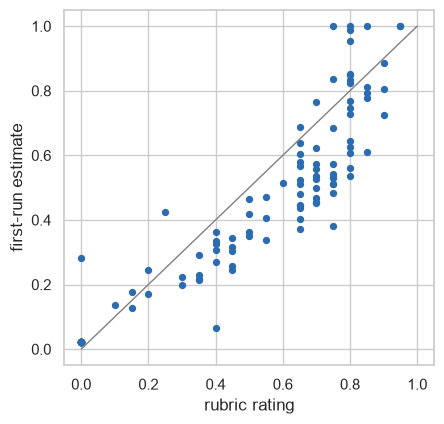

In [2]:
rows = []
for name, frame in (("real, protocol-20", real[real.rating_source == "protocol-20"]), ("real, reference", real[real.rating_source == "reference"]),
                    ("simulated", sim)):
    y = frame[LABEL].astype(float)
    rows.append({"records": name, "n": len(y), "mean": y.mean(), "sd": y.std(), "p10": y.quantile(.1), "median": y.median(), "p90": y.quantile(.9)})
display(pd.DataFrame(rows).set_index("records").round(3))
first = pd.read_csv(Path("../clean/dataset") / cfg.dataset_file, low_memory=False).set_index("record_id")
prop = first[(first.source == "real") & (first.label_source == "propagated")]
both = prop.label.astype(float).to_frame("propagated (first run)").join(real[LABEL].rename("rubric rating"))
print("The 124 real records whose label was an estimate in the first run: estimate against rubric rating")
print("  correlation %.3f | mean abs difference %.3f" % (both.corr().iloc[0, 1], (both.iloc[:, 0] - both.iloc[:, 1]).abs().mean()))
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(both["rubric rating"], both["propagated (first run)"], s=18, c="#2b6cb0")
ax.plot([0, 1], [0, 1], color="grey", lw=1); ax.set_xlabel("rubric rating"); ax.set_ylabel("first-run estimate"); fig.tight_layout(); plt.show()

## 2. Splits and baselines (validation)

In [3]:
splits = make_splits(d)
splits.to_csv(F.splits, index=False)
role = splits.join(d[["source", "label_source"]], on="record_id")
chk = role.groupby(["outer_test", "inner_val", "role"]).size().unstack(fill_value=0)
assert not ((role.role == "val") & (role.source == "synthetic")).any() and not ((role.role == "test") & (role.source == "synthetic")).any()
print("20 combinations; simulated rows are never in validation or test. Records per role (first rows):")
display(chk.head(8))
base = pd.read_csv(RES / "baseline_predictions.csv")
rows = []
for name, g in base.groupby("name"):
    m = metrics(g.y, g.pred)
    rows.append({"baseline": name, "MAE": m["MAE"], "pearson": m["pearson"], "spearman": m["spearman"], "bias": m["bias"]})
display(pd.DataFrame(rows).set_index("baseline").sort_values("MAE").round(3))

20 combinations; simulated rows are never in validation or test. Records per role (first rows):


role                  test  train  val
outer_test inner_val                  
A          B            71    220   28
           C            71    227   21
           D            71    232   16
           E            71    240    8
B          A            28    220   71
           C            28    270   21
           D            28    275   16
           E            28    283    8

,MAE,pearson,spearman,bias
baseline,,,,
ridge (5 proposal features),0.067,0.950,0.933,-0.007
tasks done (linear),0.086,0.930,0.922,-0.038
"commit count (log, linear)",0.088,0.923,0.914,-0.028
mean,0.285,-0.099,-0.096,0.008
median,0.292,-0.075,-0.077,0.103


## 3. Preprocessing: variants and label sources (Ridge, validation, selection without bias)

In [4]:
tuned = pd.read_csv(RES / "tuning_predictions.csv")
settings = json.load(open(RES / "settings.json"))
rows = []
for (variant, lab, weight), g in tuned[tuned.model == "Ridge"].groupby(["variant", "lab", "weight"]):
    p, _ = R.bias_free(g)
    m = metrics(p.y, p.pred)
    rows.append({"variant": variant, "label source": lab, "weight": weight, "MAE": m["MAE"], "pearson": m["pearson"]})
pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True).round(3)

,variant,label source,weight,MAE,pearson
0,log5 (proposal),rated only,1.0,0.071,0.951
1,"log3 (commits, lines, files)",rated only,1.0,0.082,0.934
2,log5 (proposal),rated + simulated (own ratings),0.3,0.087,0.947
3,log5 (proposal),rated + simulated (own ratings),1.0,0.094,0.948
4,"log3 (commits, lines, files)",rated + simulated (own ratings),0.3,0.096,0.934
5,"log3 (commits, lines, files)",rated + simulated (own ratings),1.0,0.105,0.935


## 4. Ridge, Random Forest and Gradient Boosting, tuned, compared without selection bias

In [5]:
choice, table, pools, picks = R.decide(cfg, tuned, base, d, RES)
table.round(3)

,model,variant,MAE,bias,pearson,spearman
0,"Ridge (rated only, LOO alpha)",proposal,0.067,-0.007,0.950,0.933
1,Ridge,log5 (proposal),0.071,0.002,0.951,0.928
2,Random Forest,log5 (proposal),0.071,-0.005,0.948,0.918
3,Random Forest,"log3 (commits, lines, files)",0.080,-0.003,0.940,0.902
4,Ridge,"log3 (commits, lines, files)",0.082,0.001,0.934,0.903
5,Gradient Boosting,log5 (proposal),0.090,0.004,0.927,0.898
6,Gradient Boosting,"log3 (commits, lines, files)",0.091,0.003,0.921,0.886


## 5. The rule for keeping a complex model

In [6]:
rule = choice["rule"]
print(f"best Ridge-type model : {rule['ridge']}  (MAE {choice['ridge_best']['MAE']:.3f})")
print(f"best tree model       : {rule['complex']}  (MAE {choice['complex_best']['MAE']:.3f})")
print(f"gain {rule['gain_mae']:+.3f} MAE, 95% interval {rule['ci'][0]:+.3f} to {rule['ci'][1]:+.3f}, better in {rule['folds_better']} of 5 folds")
chosen_name = choice["complex_best"]["model"] if rule["passes_1_3"] else choice["ridge_best"]["model"]
chosen_variant = choice["complex_best"]["variant"] if rule["passes_1_3"] else choice["ridge_best"]["variant"]
ridge_name, ridge_variant = choice["ridge_best"]["model"], choice["ridge_best"]["variant"]
print("model after rules 1-3:", chosen_name, "|", chosen_variant)

best Ridge-type model : Ridge (rated only, LOO alpha) | proposal  (MAE 0.067)
best tree model       : Random Forest | log5 (proposal)  (MAE 0.071)
gain -0.005 MAE, 95% interval -0.012 to +0.010, better in 2 of 5 folds
model after rules 1-3: Ridge (rated only, LOO alpha) | proposal


## 6. Effort only: invariants and the guard layer (rule 4)

In [7]:
final_all, fits = R.final_test(cfg, d, chosen_name, chosen_variant, tuned, settings, extra_models=[(ridge_name, ridge_variant)])
rows = []
for (model, variant) in sorted({(m, v) for (m, v, _) in fits}):
    for guarded in (False, True):
        z, mo, sp, t = R.effort_invariants(fits, model, variant, guarded)
        rows.append({"model": f"{model} | {variant}", "guard": guarded, "zero commits ~ 0": z, "never lowered by more": mo, "spam and dump <= 0.35": sp})
display(pd.DataFrame(rows))
z, mo, sp, t = R.effort_invariants(fits, chosen_name, chosen_variant, True)
display(t.round(3))
def passes(model, variant):
    z, mo, sp, _ = R.effort_invariants(fits, model, variant, True)
    return z and mo and sp
if chosen_name != ridge_name and not (passes(chosen_name, chosen_variant) or not passes(ridge_name, ridge_variant)):
    print("the tree model fails an invariant that Ridge passes: Ridge is kept")
    chosen_name, chosen_variant = ridge_name, ridge_variant
print("model for the final test:", chosen_name, "|", chosen_variant)

,model,guard,zero commits ~ 0,never lowered by more,spam and dump <= 0.35
0,"Ridge (rated only, LOO alpha) | proposal",False,True,True,False
1,"Ridge (rated only, LOO alpha) | proposal",True,True,True,False


,mean score,min over folds,max over folds
zero commits,0.000,0.000,0.000
micro-commit spam,0.241,0.223,0.269
library dump,0.343,0.324,0.381
one huge commit,0.445,0.434,0.475
many tiny real commits,0.564,0.558,0.575
typical active student,0.543,0.535,0.562
heavy contributor,0.955,0.947,0.963
largest drop when one count rises,0.000,0.000,0.000


model for the final test: Ridge (rated only, LOO alpha) | proposal


In [8]:
json.dump({**choice, "chosen": [chosen_name, chosen_variant]}, open(RES / "model_choice.json", "w"), indent=1, default=float)
print("model for the final test:", chosen_name, "|", chosen_variant)

model for the final test: Ridge (rated only, LOO alpha) | proposal


## 7. Final test, scored once

In [9]:
final, fits = R.final_test(cfg, d, chosen_name, chosen_variant, tuned, settings)
final.to_csv(RES / "final_test_predictions_unguarded.csv", index=False)
MAIN = f"{chosen_name} | {chosen_variant}"
GUARDED = MAIN + " + guard"
fg = final[final.name == MAIN].copy()
fg["name"] = GUARDED
fg["pred"] = np.concatenate([R.predict_with(fits[(chosen_name, chosen_variant, o)], d.loc[fg[fg.outer_test == o].record_id], True) for o in GROUPS])
final = pd.concat([final, fg], ignore_index=True)
final.to_csv(RES / "final_test_predictions.csv", index=False)
print("the pipeline's form is the guarded one (protocol); unguarded results are in the table below")
MAIN = GUARDED
fold_info = pd.DataFrame({o: fits[(chosen_name, chosen_variant, o)][2] for o in GROUPS}).T
display(fold_info)
print(len(final[final.name == MAIN]), "test predictions from", len(GROUPS), "models, each made by a model that never saw that student")

the pipeline's form is the guarded one (protocol); unguarded results are in the table below


,alpha,label_config
A,1.0,rated only
B,1.0,rated only
C,3.162278,rated only
D,3.162278,rated only
E,3.162278,rated only


144 test predictions from 5 models, each made by a model that never saw that student


In [10]:
crit, m = R.criteria_table(cfg, final, MAIN, d)
crit.to_csv(RES / "final_test_criteria.csv", index=False)
print("PRIMARY: all %d real records" % len(final[final.name == MAIN]))
display(crit.round(3))
f20 = final[final.record_id.isin(P20)]
crit20, m20 = R.criteria_table(cfg, f20, MAIN, d)
crit20.to_csv(RES / "final_test_criteria_original20.csv", index=False)
print("SECONDARY: the original 20 records only (%d)" % len(f20[f20.name == MAIN]))
display(crit20.round(3))

PRIMARY: all 144 real records


,criterion,value,minimum,target,verdict,note
0,MAE,0.069933,<= 0.11,<= 0.08,target met,95% interval 0.058-0.091
1,Pearson and Spearman,0.944 / 0.927,>= 0.8 both,>= 0.9 / 0.85,target met,
2,"Beats commit count (log, linear)",gain +0.017 (+20%),interval of the gain excludes 0,>= 10% lower,NOT MET,95% interval -0.000 to +0.048
3,Bias,-0.020091,within +-0.05,within +-0.03,target met,
4,Calibration slope,0.954143,0.7-1.3,0.8-1.2,target met,
5,Rubric bands within one,0.979167,>= 85%,">= 90%, exact >= 50%",target met,exact 74%
6,"MAE, students with activity",0.090099,<= 0.12,<= 0.1,target met,n = 104


SECONDARY: the original 20 records only (20)


,criterion,value,minimum,target,verdict,note
0,MAE,0.083799,<= 0.11,<= 0.08,minimum met,95% interval 0.048-0.105
1,Pearson and Spearman,0.960 / 0.946,>= 0.8 both,>= 0.9 / 0.85,target met,
2,"Beats commit count (log, linear)",gain -0.021 (-34%),interval of the gain excludes 0,>= 10% lower,NOT MET,95% interval -0.041 to +0.010
3,Bias,0.058243,within +-0.05,within +-0.03,NOT MET,
4,Calibration slope,0.85188,0.7-1.3,0.8-1.2,target met,
5,Rubric bands within one,1.0,>= 85%,">= 90%, exact >= 50%",target met,exact 80%
6,"MAE, students with activity",0.101732,<= 0.12,<= 0.1,minimum met,n = 15


,MAE,pearson,spearman,bias
model,,,,
"Ridge (rated only, LOO alpha) | proposal",0.069,0.953,0.932,0.001
"Ridge (rated only, LOO alpha) | proposal + guard",0.070,0.944,0.927,-0.020
tasks done (linear),0.086,0.930,0.922,-0.039
"commit count (log, linear)",0.087,0.924,0.913,-0.028
mean,0.284,-0.184,-0.123,0.007
median,0.292,-0.107,-0.124,0.092


outer_test,A,B,C,D,E
n,71.000,28.00,21.000,16.000,8.000
MAE,0.062,0.07,0.089,0.104,0.021


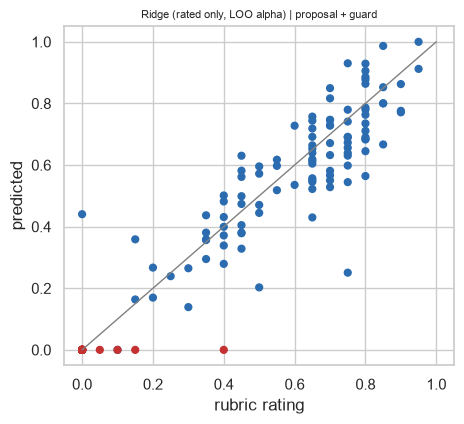

In [11]:
rows = []
for name, g in final.groupby("name"):
    mm = metrics(g.y, g.pred)
    rows.append({"model": name, "MAE": mm["MAE"], "pearson": mm["pearson"], "spearman": mm["spearman"], "bias": mm["bias"]})
display(pd.DataFrame(rows).set_index("model").sort_values("MAE").round(3))
pf = final[final.name == MAIN].assign(err=lambda x: (x.pred - x.y).abs())
display(pf.groupby("outer_test").agg(n=("err", "size"), MAE=("err", "mean")).round(3).T)
f = final[final.name == MAIN]
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(f.y, f.pred, c=np.where(f.activity > 0, "#2b6cb0", "#c53030"), s=24)
ax.plot([0, 1], [0, 1], color="grey", lw=1)
ax.set_xlabel("rubric rating"); ax.set_ylabel("predicted"); ax.set_title(MAIN, fontsize=8)
fig.tight_layout(); plt.show()

## 8. Beside the first clean run and the uncleaned experiments

In [12]:
print("First clean run (labels: 20 ratings + estimates), criteria table:")
display(pd.read_csv(Path("../clean/training/results/final_test_criteria.csv")).round(3))
print("Uncleaned experiments (old features, 20 ratings), criteria table:")
display(pd.read_csv(Path("../training/results/final_test_criteria.csv")).round(3))

First clean run (labels: 20 ratings + estimates), criteria table:


,criterion,value,minimum,target,verdict,note
0,MAE,0.05899512569366709,<= 0.11,<= 0.08,target met,95% interval 0.038-0.075
1,Pearson and Spearman,0.952 / 0.900,>= 0.8 both,>= 0.9 / 0.85,target met,NaN
2,"Beats commit count (log, linear)",gain -0.002 (-3%),interval of the gain excludes 0,>= 10% lower,NOT MET,95% interval -0.008 to +0.004
3,Bias,-0.008376908261333377,within +-0.05,within +-0.03,target met,NaN
4,Calibration slope,0.9868461310018127,0.7-1.3,0.8-1.2,target met,NaN
5,Rubric bands within one,1.0,>= 85%,">= 90%, exact >= 50%",target met,exact 80%
6,"MAE, students with activity",0.06866016759155613,<= 0.12,<= 0.1,target met,n = 15


Uncleaned experiments (old features, 20 ratings), criteria table:


,criterion,result,minimum (works),target,meets minimum,meets target
0,MAE,0.069,<= 0.11,<= 0.08,True,True
1,Pearson,0.931,>= 0.80,>= 0.90,True,True
2,Spearman,0.931,>= 0.80,>= 0.85,True,True
3,Beats commit count alone,gain -0.015 (95% CI -0.052 to 0.011),interval excludes 0,and >= 10% lower MAE,False,False
4,Bias,-0.010,within +-0.05,within +-0.03,True,True
5,Calibration slope,1.15,0.7 - 1.3,0.8 - 1.2,True,True
6,Rubric bands within one,100%,>= 85%,>= 90%,True,True
7,Rubric bands exact,55%,-,>= 50%,True,True
8,"MAE, records with activity",0.081,<= 0.12,<= 0.10,True,True


## 9. Reading the results

_Reading of the results: written after the run._